# 2 · Multi-objective optimization

Many lab goals trade off against each other — maximize yield *and* minimize cost.
abbot is **natively multi-objective**: declare several objectives (each with its
own direction) and `ParetoBO` searches for the Pareto front rather than collapsing
everything to one number.

In [1]:
import torch, warnings
warnings.filterwarnings("ignore")
from abbot import (
    ProblemSpec, ContinuousDomain, OutputSpec, run_campaign, MockAnalyticExperiment,
)
torch.manual_seed(0)

### A two-objective problem
`f1` to maximize and `f2` to maximize, over a 2-D design space. (Directions are
declared per output; abbot handles the signs internally — you always report
raw physical values.)

In [2]:
spec = ProblemSpec(
    domain=[
        ContinuousDomain(name="x1", lower=0.0, upper=1.0),
        ContinuousDomain(name="x2", lower=0.0, upper=1.0),
    ],
    outputs=[
        OutputSpec(name="f1", direction="MAXIMIZE"),
        OutputSpec(name="f2", direction="MAXIMIZE"),
    ],
)
experiment = MockAnalyticExperiment(spec, seed=5)  # two bumps peaking in different places

Two objectives, so `run_campaign` picks `ParetoBO` and an independent GP per
output (`ModelListConstructor`) on its own — the call is the same as notebook 1.

_(ParetoBO's hypervolume acquisition is the heaviest policy — a small budget keeps this notebook to a few seconds; raise `n_shots` for a denser front.)_

In [3]:
result = run_campaign(spec, experiment, n_shots=8)
print("Pareto set size:", len(result.recommended))

Pareto set size: 7


### The recovered Pareto front
Each recommended design is non-dominated: you can't improve one objective without sacrificing the other.

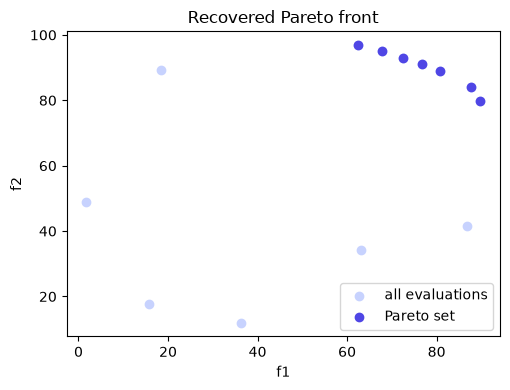

In [4]:
import matplotlib.pyplot as plt

all_Y = result.history.outputs.numpy()
front = result.designs  # recommended designs
front_Y = result.history.outputs[result.recommended].numpy()

plt.figure(figsize=(5.2, 4))
plt.scatter(all_Y[:, 0], all_Y[:, 1], c="#c7d2fe", label="all evaluations")
plt.scatter(front_Y[:, 0], front_Y[:, 1], c="#4f46e5", label="Pareto set", zorder=3)
plt.xlabel("f1"); plt.ylabel("f2"); plt.title("Recovered Pareto front")
plt.legend(); plt.tight_layout(); plt.show()

**What this showed:** with two competing objectives, abbot returns a *set* of
non-dominated designs (the trade-off frontier) rather than a single answer — the
scientist picks the operating point that suits them.